In [1]:
"""
STEP 3: Local Models
===============================================
Approach:
- Train ONE model per z-height
- Each model has x_norm as INPUT feature
- Input:  [x_norm, U_ref, profile_type_onehot] → 6 features  (+optional [flow_regime_onehot] → 6 features)
- Output: U_x at that specific z-height
- Training: ~64 points per model (8 x-locations × 8 cases)

Feature Engineering:
- x_norm = x / H_CUBE (physics-based, in cube heights)
- z_norm = z / H_CUBE (for reference, not used as input in local models)
- profile_type: one-hot encoded [Uniform, ABL+constant, ABL+free, ABL+laminar]

Validation:
- Option 1: K-fold cross-validation (standard)
- Option 2: Spatial test (hold out x-locations)
- Option 3: Case test (hold out inlet conditions)¨

Models:
- LNU: Linear (6 inputs + bias = 7 params)
- QNU: Quadratic (28 params with interactions)
- MLP: Neural network (~50-100 params)

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR  
import sys

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy import stats
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings('ignore')



In [102]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_101.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform_1case.pkl'

OUTPUT_DIR = RESULTS_DIR

H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075  # meters
X_CUBE_BACK = 0.090  # meters

# Validation strategy
VALIDATION_MODE = 'spatial'  # Options: 'cv', 'spatial', 'case'

# Model settings
RANDOM_STATE = 42

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

In [103]:
# ============================================================================
# FEATURE CONFIGURATION
# ============================================================================

# OPTIONAL FEATURE
USE_FLOW_REGIME = False   # Set to True to add flow_regime as feature
                         # False: 6 features [x_norm, U_ref, profile_type(4)]
                         # True:  10 features [x_norm, U_ref, profile_type(4), flow_regime(4)]

# Profile type mapping (for one-hot encoding)
PROFILE_TYPE_MAP = {
    0: 'Uniform',
    1: 'ABL+constant',
    2: 'ABL+free',
    3: 'ABL+laminar'
}
N_PROFILE_TYPES = 4

# Flow regime mapping (for one-hot encoding)
FLOW_REGIME_MAP = {
    0: 'upstream',
    1: 'over_cube',
    2: 'wake',
    3: 'far_downstream'
}
N_FLOW_REGIMES = 4

# Flow regime boundaries
X_RECOVERY = 0.20  # meters - approximate start of recovered flow = almost fully recovered
X_RECOVERY = 0.14  # meters - approximate start of recovered flow = reattachment no negative U_x values

def get_flow_regime(x_loc):
    """Determine flow regime based on x-location"""
    if x_loc < X_CUBE_FRONT:
        return 0  # upstream
    elif x_loc <= X_CUBE_BACK:
        return 1  # over_cube
    elif x_loc < X_RECOVERY:
        return 2  # wake
    else:
        return 3  # far_downstream

# Feature names for documentation (depends on USE_FLOW_REGIME)
if USE_FLOW_REGIME:
    FEATURE_NAMES = ['x_norm', 'U_ref', 
                     'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam',
                     'regime_upstream', 'regime_over_cube', 'regime_wake', 'regime_far_downstream']
else:
    FEATURE_NAMES = ['x_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']

N_FEATURES = len(FEATURE_NAMES)

print("="*80)
print(" "*15 + "STEP 3: LOCAL MODELS (UPDATED FEATURES)")
print("="*80)
print(f"\nStrategy: One model per z-height, with x_norm as input")
print(f"\n✅ NEW FEATURE SET:")
print(f"   • x_norm = x / H_CUBE (physics-based normalization)")
print(f"   • U_ref (reference velocity)")
print(f"   • profile_type (one-hot encoded, 4 categories)")
print(f"   • Total: {N_FEATURES} features")
print(f"\nValidation mode: {VALIDATION_MODE}")


               STEP 3: LOCAL MODELS (UPDATED FEATURES)

Strategy: One model per z-height, with x_norm as input

✅ NEW FEATURE SET:
   • x_norm = x / H_CUBE (physics-based normalization)
   • U_ref (reference velocity)
   • profile_type (one-hot encoded, 4 categories)
   • Total: 6 features

Validation mode: spatial


In [104]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\n{'='*80}")
print("LOADING DATA")
print("="*80)

# Load CFD data
with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")


LOADING DATA
✓ Loaded 1 cases


In [105]:
# ============================================================================
# EXTRACT CASE PARAMETERS
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING CASE PARAMETERS (SIMPLIFIED)")
print("="*80)
print("\n✅ Using profile_type (categorical) instead of α, δ fitting")

case_parameters = {}
for case_id, case_data in all_cases_data.items():
    case_parameters[case_id] = {
        'U_ref': case_data['U_ref'],
        'profile_type': case_data['profile_type'],  # Integer: 0, 1, 2, or 3
        'profile_name': case_data['profile_name'],
    }
    print(f"  {case_id:20s}: U_ref={case_data['U_ref']:.1f}, type={case_data['profile_type']} ({case_data['profile_name']})")

print(f"\n✓ Extracted parameters for {len(case_parameters)} cases")



EXTRACTING CASE PARAMETERS (SIMPLIFIED)

✅ Using profile_type (categorical) instead of α, δ fitting
  U5_ABL_lam          : U_ref=5.1, type=3 (ABL+laminar)

✓ Extracted parameters for 1 cases


In [106]:
# ============================================================================
# ONE-HOT ENCODING SETUP
# ============================================================================

print(f"\n{'='*80}")
print("ONE-HOT ENCODING FOR PROFILE TYPE")
print("="*80)

# Create one-hot encoder for profile_type
profile_types_all = np.array([[cp['profile_type']] for cp in case_parameters.values()])
onehot_encoder_profile = OneHotEncoder(sparse_output=False, categories='auto')
onehot_encoder_profile.fit(profile_types_all)

print(f"\n✓ Profile type one-hot encoder fitted")
print(f"  Categories: {onehot_encoder_profile.categories_[0]}")
print(f"  Example encoding:")
for ptype in range(N_PROFILE_TYPES):
    encoding = onehot_encoder_profile.transform([[ptype]])[0]
    print(f"    Type {ptype} ({PROFILE_TYPE_MAP[ptype]:12s}): {encoding}")

    
# Create one-hot encoder for flow_regime (if enabled)
if USE_FLOW_REGIME:
    flow_regimes_all = np.array([[i] for i in range(N_FLOW_REGIMES)])
    onehot_encoder_regime = OneHotEncoder(sparse_output=False, categories='auto')
    onehot_encoder_regime.fit(flow_regimes_all)
    
    print(f"\n✓ Flow regime one-hot encoder fitted")
    print(f"  Categories: {onehot_encoder_regime.categories_[0]}")
    print(f"  Example encoding:")
    for regime in range(N_FLOW_REGIMES):
        encoding = onehot_encoder_regime.transform([[regime]])[0]
        print(f"    Regime {regime} ({FLOW_REGIME_MAP[regime]:15s}): {encoding}")
else:
    onehot_encoder_regime = None
    print(f"\n⚠️  Flow regime encoding: DISABLED")



ONE-HOT ENCODING FOR PROFILE TYPE

✓ Profile type one-hot encoder fitted
  Categories: [3]
  Example encoding:


ValueError: Found unknown categories [0] in column 0 during transform

In [116]:
# ============================================================================
# AUTOMATIC TRAIN/TEST SPLIT (Proportional by Flow Regime)
# ============================================================================

print(f"\n{'='*80}")
print("TRAIN/TEST SPLIT BY FLOW REGIME")
print("="*80)

all_x_locations = sorted(list(set([x for case_data in all_cases_data.values() 
                                     for x in case_data['profiles'].keys()])))

print(f"\nAvailable x-locations: {len(all_x_locations)}")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in all_x_locations]}")

# Categorize by flow regime
X_RECOVERY = 0.14

regime_locations = {
    'upstream': [],
    'over_cube': [],
    'wake': [],
    'far_downstream': []
}

for x in all_x_locations:
    if x < X_CUBE_FRONT:
        regime_locations['upstream'].append(x)
    elif x <= X_CUBE_BACK:
        regime_locations['over_cube'].append(x)
    elif x < X_RECOVERY:
        regime_locations['wake'].append(x)
    else:
        regime_locations['far_downstream'].append(x)

print(f"\n📍 Locations by flow regime:")
for regime, locs in regime_locations.items():
    x_H = [f'{x/H_CUBE:.1f}' for x in locs]
    print(f"  {regime:15s}: {len(locs):2d} locations  (x/H: {x_H})")


# TEST SELECTION STRATEGY
# Option 1: Fixed 1 per regime (current)
# Option 2: Proportional (~20% from each regime)
# Option 3: Fixed total percentage

TEST_STRATEGY = 'proportional'  # Options: 'one_per_regime', 'proportional', 'percentage'
TEST_FRACTION = 0.2  # For 'proportional' and 'percentage' strategies

x_test = []
test_selection = {}

if TEST_STRATEGY == 'one_per_regime':
    # Original: 1 test location per regime (always 4 total)
    for regime, locs in regime_locations.items():
        if len(locs) >= 2:
            mid_idx = len(locs) // 2
            x_test.append(locs[mid_idx])
            test_selection[regime] = [locs[mid_idx]]
        elif len(locs) == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'proportional':
    # Proportional: ~20% from each regime, minimum 1 if regime has ≥3 points
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 3:
            # Take ~20% but at least 1
            n_test = max(1, int(n_locs * TEST_FRACTION))
            # Select evenly spaced indices (not edges)
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                # Avoid first and last, distribute evenly
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        elif n_locs == 2:
            # Take middle-ish (index 1)
            x_test.append(locs[1])
            test_selection[regime] = [locs[1]]
        elif n_locs == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'percentage':
    # Simple percentage of total, distributed across regimes
    n_total_test = max(4, int(len(all_x_locations) * TEST_FRACTION))
    # Distribute proportionally to regime size
    total_locs = sum(len(locs) for locs in regime_locations.values())
    
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 2:
            # Proportion of test points for this regime
            n_test = max(1, int(n_total_test * n_locs / total_locs))
            # Select from middle
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        else:
            test_selection[regime] = []

x_train = [x for x in all_x_locations if x not in x_test]
x_train = sorted(x_train)
x_test = sorted(x_test)


# SUMMARY
print(f"\n{'─'*60}")
print(f"TEST STRATEGY: {TEST_STRATEGY}")
print(f"{'─'*60}")

print(f"\n✓ Test locations by regime:")
for regime, locs in test_selection.items():
    if locs:
        x_H = [f'{x/H_CUBE:.1f}' for x in locs]
        print(f"  {regime:15s}: {len(locs):2d} test  (x/H: {x_H})")
    else:
        print(f"  {regime:15s}:  0 test")

print(f"\n✓ Training: {len(x_train)} x-locations ({100*len(x_train)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_train]}")

print(f"\n✓ Testing: {len(x_test)} x-locations ({100*len(x_test)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_test]}")


TRAIN/TEST SPLIT BY FLOW REGIME

Available x-locations: 25
  x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4', '5.2', '6.1', '7.0', '7.9', '8.8', '9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0']

📍 Locations by flow regime:
  upstream       :  6 locations  (x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4'])
  over_cube      :  1 locations  (x/H: ['5.2'])
  wake           :  4 locations  (x/H: ['6.1', '7.0', '7.9', '8.8'])
  far_downstream : 14 locations  (x/H: ['9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0'])
  ⚠️  over_cube: Only 1 location, keeping for training

────────────────────────────────────────────────────────────
TEST STRATEGY: proportional
────────────────────────────────────────────────────────────

✓ Test locations by regime:
  upstream       :  1 test  (x/H: ['2.6'])
  over_cube      :  0 test
  wake           :  1 test  (x/H: ['7.9'])
  far_downstrea

In [117]:
# ============================================================================
# HELPER FUNCTION: CREATE FEATURE VECTOR
# ============================================================================

def create_feature_vector(x_loc, U_ref, profile_type, 
                          onehot_encoder_profile, H_CUBE,
                          use_flow_regime=False, onehot_encoder_regime=None):
    """
    Create feature vector for model input.
    
    BASE FEATURES (always included):
    - x_norm = x / H_CUBE (physics-based)
    - U_ref (as-is)
    - profile_type (one-hot encoded, 4 values)
    
    OPTIONAL FEATURES:
    - flow_regime (one-hot encoded, 4 values) - if use_flow_regime=True
    
    Total: 6 features (base) or 10 features (with flow_regime)
    """
    # Physics-based normalization
    x_norm = x_loc / H_CUBE
    
    # One-hot encode profile type
    profile_onehot = onehot_encoder_profile.transform([[profile_type]])[0]
    
    # Base features: [x_norm, U_ref, onehot[0], onehot[1], onehot[2], onehot[3]]
    features = np.concatenate([[x_norm, U_ref], profile_onehot])
    
    # Optional: add flow_regime
    if use_flow_regime and onehot_encoder_regime is not None:
        flow_regime = get_flow_regime(x_loc)
        regime_onehot = onehot_encoder_regime.transform([[flow_regime]])[0]
        features = np.concatenate([features, regime_onehot])
    
    return features

# Test the function
print(f"\n✓ Feature vector function created")
test_features = create_feature_vector(
    x_loc=0.1, U_ref=5.1, profile_type=2,
    onehot_encoder_profile=onehot_encoder_profile, H_CUBE=H_CUBE,
    use_flow_regime=USE_FLOW_REGIME, onehot_encoder_regime=onehot_encoder_regime
)
print(f"  Example: x=0.1m (x/H={0.1/H_CUBE:.1f}), U_ref=5.1, type=2 (ABL+free)")
if USE_FLOW_REGIME:
    regime = get_flow_regime(0.1)
    print(f"           flow_regime={regime} ({FLOW_REGIME_MAP[regime]})")
print(f"  Features ({len(test_features)}): {test_features}")
print(f"  Names: {FEATURE_NAMES}")


✓ Feature vector function created


ValueError: Found unknown categories [2] in column 0 during transform


CREATING DATA DISTRIBUTION VISUALIZATION
DATA SPLIT SUMMARY:
Training locations: 21
Testing locations:  4
Total cases: 1
Training points per z-height: 21 x-locs × 1 cases = 21 points
Testing points per z-height: 4 x-locs × 1 cases = 4 points


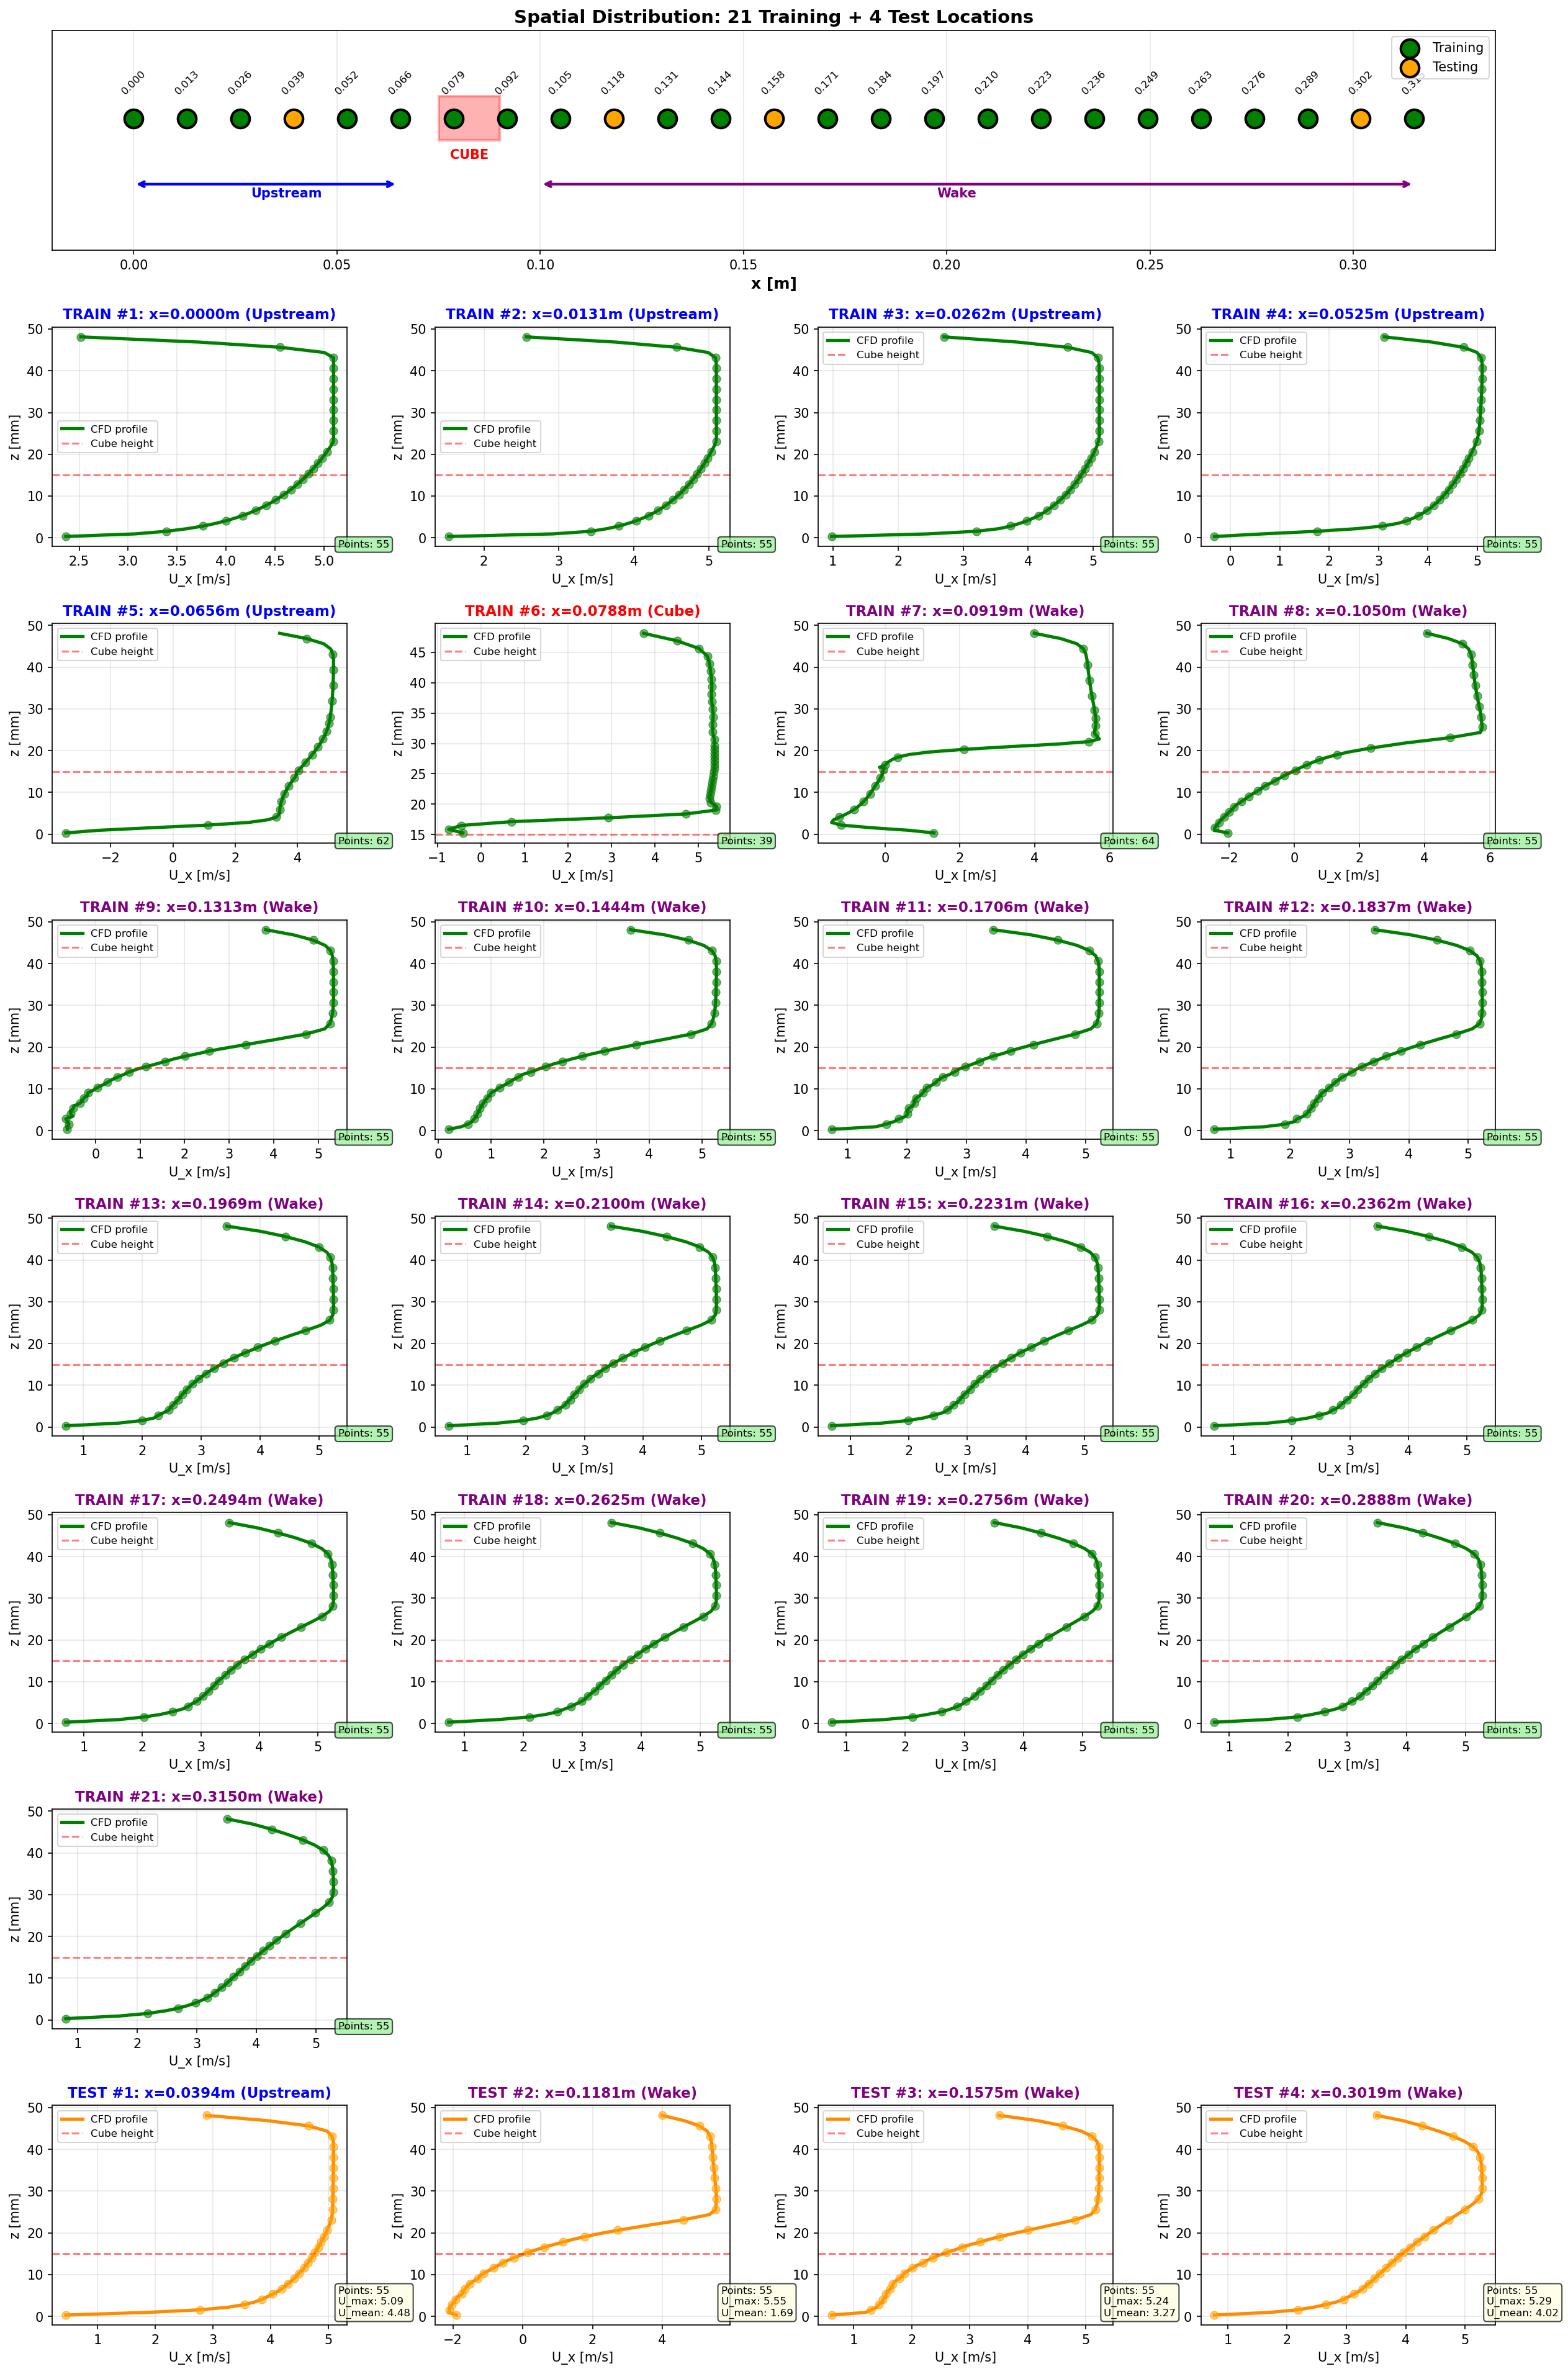

✓ Saved: step3_data_distribution.png



In [118]:
# ============================================================================
# VISUALIZATION 0: TRAINING AND TEST DATA DISTRIBUTION (ALL PROFILES)
# ============================================================================

print(f"\n{'='*80}")
print("CREATING DATA DISTRIBUTION VISUALIZATION")
print("="*80)

# Get a representative case for visualization
viz_case_id = list(all_cases_data.keys())[0]
viz_case = all_cases_data[viz_case_id]

# Calculate layout: 1 row for domain + rows for all training + row for test
n_train = len(x_train)
n_test = len(x_test)
n_cols = 4  # 4 columns for profile plots
n_train_rows = int(np.ceil(n_train / n_cols))
n_test_rows = int(np.ceil(n_test / n_cols))
total_rows = 1 + n_train_rows + n_test_rows  # domain + training + testing

fig = plt.figure(figsize=(20, 4 + 4*n_train_rows + 4*n_test_rows))
gs = fig.add_gridspec(total_rows, n_cols, hspace=0.35, wspace=0.3)

# ============================================================================
# TOP: DOMAIN LAYOUT WITH TRAINING/TEST LOCATIONS
# ============================================================================

ax_domain = fig.add_subplot(gs[0, :])

# Plot all available x-locations
all_x = sorted(viz_case['profiles'].keys())
y_pos = [1] * len(all_x)

# Color code: training (green), testing (orange), unused (gray)
colors = []
labels_added = {'train': False, 'test': False, 'unused': False}

for x in all_x:
    if x in x_train:
        colors.append('green')
        label = 'Training' if not labels_added['train'] else ''
        labels_added['train'] = True
    elif x in x_test:
        colors.append('orange')
        label = 'Testing' if not labels_added['test'] else ''
        labels_added['test'] = True
    else:
        colors.append('lightgray')
        label = 'Unused' if not labels_added['unused'] else ''
        labels_added['unused'] = True
    
    ax_domain.scatter(x, 1, c=colors[-1], s=200, marker='o', 
                     edgecolors='black', linewidth=2, zorder=3, label=label)
    ax_domain.text(x, 1.05, f'{x:.3f}', ha='center', va='bottom', 
                  fontsize=8, rotation=45)

# Draw cube
cube_start = 0.075
cube_end = 0.075 + H_CUBE
ax_domain.add_patch(plt.Rectangle((cube_start, 0.95), H_CUBE, 0.1, 
                                  facecolor='red', alpha=0.3, 
                                  edgecolor='red', linewidth=2))
ax_domain.text(cube_start + H_CUBE/2, 0.93, 'CUBE', ha='center', 
              va='top', fontsize=10, fontweight='bold', color='red')

# Annotations
ax_domain.annotate('', xy=(0, 0.85), xytext=(cube_start-0.01, 0.85),
                  arrowprops=dict(arrowstyle='<->', color='blue', lw=2))
ax_domain.text(cube_start/2, 0.82, 'Upstream', ha='center', 
              fontsize=10, color='blue', fontweight='bold')

ax_domain.annotate('', xy=(cube_end+0.01, 0.85), xytext=(max(all_x), 0.85),
                  arrowprops=dict(arrowstyle='<->', color='purple', lw=2))
ax_domain.text((cube_end + max(all_x))/2, 0.82, 'Wake', ha='center', 
              fontsize=10, color='purple', fontweight='bold')

ax_domain.set_xlim(-0.02, max(all_x) + 0.02)
ax_domain.set_ylim(0.7, 1.2)
ax_domain.set_xlabel('x [m]', fontsize=12, fontweight='bold')
ax_domain.set_yticks([])
ax_domain.set_title(f'Spatial Distribution: {n_train} Training + {n_test} Test Locations', 
                   fontsize=14, fontweight='bold')
ax_domain.legend(loc='upper right', fontsize=10)
ax_domain.grid(axis='x', alpha=0.3)

# ============================================================================
# MIDDLE: TRAINING PROFILES
# ============================================================================

for idx, x_loc in enumerate(x_train):
    row = 1 + idx // n_cols
    col = idx % n_cols
    ax = fig.add_subplot(gs[row, col])
    
    if x_loc in viz_case['profiles']:
        profile = viz_case['profiles'][x_loc]
        z = profile['z']
        U = profile['U_x']
        
        ax.plot(U, z*1000, 'g-', linewidth=2.5, label='CFD profile')
        ax.scatter(U[::max(1, len(U)//20)], z[::max(1, len(z)//20)]*1000, 
                  c='green', s=40, alpha=0.6, zorder=3, edgecolors='darkgreen', linewidth=0.5)
        
        # Mark cube height
        ax.axhline(H_CUBE*1000, color='red', linestyle='--', 
                  alpha=0.5, linewidth=1.5, label='Cube height')
        
        # Indicate region
        if x_loc < cube_start:
            region = 'Upstream'
            region_color = 'blue'
        elif x_loc <= cube_end:
            region = 'Cube'
            region_color = 'red'
        else:
            region = 'Wake'
            region_color = 'purple'
        
        ax.set_title(f'TRAIN #{idx+1}: x={x_loc:.4f}m ({region})', 
                    fontsize=11, fontweight='bold', color=region_color)
        ax.set_xlabel('U_x [m/s]', fontsize=10)
        ax.set_ylabel('z [mm]', fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, loc='best')
        
        # Add statistics
        U_max = U.max()
        U_mean = U.mean()
        n_points = len(z)
        textstr = f'Points: {n_points}'
        ax.text(0.97, 0.03, textstr, transform=ax.transAxes,
               fontsize=8, verticalalignment='top', horizontalalignment='left',
               bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# ============================================================================
# BOTTOM: TEST PROFILES
# ============================================================================

test_row_start = 1 + n_train_rows

for idx, x_loc in enumerate(x_test):
    row = test_row_start + idx // n_cols
    col = idx % n_cols
    ax = fig.add_subplot(gs[row, col])
    
    if x_loc in viz_case['profiles']:
        profile = viz_case['profiles'][x_loc]
        z = profile['z']
        U = profile['U_x']
        
        ax.plot(U, z*1000, color='darkorange', linewidth=2.5, label='CFD profile')
        ax.scatter(U[::max(1, len(U)//20)], z[::max(1, len(z)//20)]*1000, 
                  c='orange', s=40, alpha=0.6, zorder=3, edgecolors='darkorange', linewidth=0.5)
        
        # Mark cube height
        ax.axhline(H_CUBE*1000, color='red', linestyle='--', 
                  alpha=0.5, linewidth=1.5, label='Cube height')
        
        # Indicate region
        if x_loc < cube_start:
            region = 'Upstream'
            region_color = 'blue'
        elif x_loc <= cube_end:
            region = 'Cube'
            region_color = 'red'
        else:
            region = 'Wake'
            region_color = 'purple'
        
        ax.set_title(f'TEST #{idx+1}: x={x_loc:.4f}m ({region})', 
                    fontsize=11, fontweight='bold', color=region_color)
        ax.set_xlabel('U_x [m/s]', fontsize=10)
        ax.set_ylabel('z [mm]', fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, loc='best')
        
        # Add statistics
        U_max = U.max()
        U_mean = U.mean()
        n_points = len(z)
        textstr = f'Points: {n_points}\nU_max: {U_max:.2f}\nU_mean: {U_mean:.2f}'
        ax.text(0.97, 0.03, textstr, transform=ax.transAxes,
               fontsize=8, verticalalignment='bottom', horizontalalignment='left',
               bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))


# Add summary text
print("DATA SPLIT SUMMARY:")
print(f'Training locations: {len(x_train)}')
print(f'Testing locations:  {len(x_test)}')
print(f'Total cases: {len(all_cases_data)}')
      
print(f'Training points per z-height: {len(x_train)} x-locs × {len(all_cases_data)} cases = {len(x_train) * len(all_cases_data)} points')

print(f'Testing points per z-height: {len(x_test)} x-locs × {len(all_cases_data)} cases = {len(x_test) * len(all_cases_data)} points')

plt.savefig(FIGURES_DIR / 'step3_data_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_data_distribution.png")
plt.close()

print(f"\n{'='*80}")



In [119]:
# ============================================================================
# EXTRACT ALL UNIQUE Z-POINTS FROM CFD DATA
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING ALL CFD Z-POINTS")
print("="*80)

# Collect ALL unique z-points from ALL training locations
all_z_points = set()
for case_data in all_cases_data.values():
    for x_loc in x_train:
        if x_loc in case_data['profiles']:
            z = case_data['profiles'][x_loc]['z']
            all_z_points.update(z)

z_heights = np.array(sorted(all_z_points))

print(f"\n✓ Found {len(z_heights)} unique z-points")
print(f"  Range: [{z_heights[0]:.6f}, {z_heights[-1]:.6f}] m")
print(f"  Average spacing: {np.mean(np.diff(z_heights))*1000:.6f} mm")
print(f"  Min spacing: {np.min(np.diff(z_heights))*1000:.6f} mm")
print(f"  Max spacing: {np.max(np.diff(z_heights))*1000:.6f} mm")



EXTRACTING ALL CFD Z-POINTS

✓ Found 170 unique z-points
  Range: [0.000312, 0.048125] m
  Average spacing: 0.282914 mm
  Min spacing: 0.000008 mm
  Max spacing: 1.250000 mm


In [120]:
# ============================================================================
# EXTRACT TRAINING DATA
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING TRAINING DATA")
print("="*80)
print(f"\n✅ Features: {FEATURE_NAMES}")

# Create training dataset for each z-height
training_data = {}

for z_target in z_heights:
    X_data = []
    y_data = []
    
    for case_id, case_data in all_cases_data.items():
        params = case_parameters[case_id]
        
        for x_loc in x_train:
            if x_loc in case_data['profiles']:
                profile = case_data['profiles'][x_loc]
                z_profile = profile['z']
                U_profile = profile['U_x']
                
                # Find match
#                 matches = np.abs(z_profile - z_target) < 1e-10     #  small tolerance for floating point comparison 
                matches = np.abs(z_profile - z_target) < 0.0003125   # tolerance 
                                                                      # 0.0003125 - fine mesh dx
                                                                      # 0.0006250 - mid mesh dx
                                                                      # 0.0012500 - coarse mesh dx
                if matches.any():
                    idx = np.where(matches)[0][0]
                    U_x = U_profile[idx]
                    
                    # CREATE NEW FEATURE VECTOR
                    features = create_feature_vector(
                        x_loc=x_loc,
                        U_ref=params['U_ref'],
                        profile_type=params['profile_type'],
                        onehot_encoder_profile=onehot_encoder_profile,
                        H_CUBE=H_CUBE,
                        use_flow_regime=USE_FLOW_REGIME,
                        onehot_encoder_regime=onehot_encoder_regime
                    )
                    
                    X_data.append(features)
                    y_data.append(U_x)
    
    if len(X_data) > 0:
        training_data[z_target] = {
            'X': np.array(X_data),
            'y': np.array(y_data)
        }


# Remove z-heights with insufficient data
z_heights_original = len(z_heights)
z_heights = np.array([z for z in z_heights if z in training_data])

print(f"\n✓ Extracted training data for {len(z_heights)} z-heights")
print(f"  Removed {z_heights_original - len(z_heights)} z-heights with insufficient data")

# Check data distribution
data_counts = [len(training_data[z]['X']) for z in z_heights]
print(f"\nTraining points per z-height:")
print(f"  Min: {min(data_counts)}")
print(f"  Max: {max(data_counts)}")
print(f"  Mean: {np.mean(data_counts):.1f}")

# Verify first z-height
if len(z_heights) > 0:
    train_points = len(training_data[z_heights[0]]['X'])
    print(f"\nFirst z-height ({z_heights[0]:.6f} m): {train_points} points")

# Verify feature dimensions
print(f"\nFeature verification:")
print(f"  Feature shape: {training_data[z_heights[0]]['X'].shape}")
print(f"  Expected: (n_samples, {N_FEATURES})")
print(f"  Feature names: {FEATURE_NAMES}")



EXTRACTING TRAINING DATA

✅ Features: ['x_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']

✓ Extracted training data for 170 z-heights
  Removed 0 z-heights with insufficient data

Training points per z-height:
  Min: 2
  Max: 21
  Mean: 18.0

First z-height (0.000312 m): 20 points

Feature verification:
  Feature shape: (20, 3)
  Expected: (n_samples, 6)
  Feature names: ['x_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']


In [121]:
# ============================================================================
# TRAIN MODELS AT EACH Z-HEIGHT
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING MODELS")
print("="*80)
print(f"\n✅ Using {N_FEATURES} features: {FEATURE_NAMES}")

models = {}
metrics = {}
feature_scaler = StandardScaler()

# Fit scaler on all training data
all_X = np.vstack([training_data[z]['X'] for z in z_heights])
feature_scaler.fit(all_X)

print(f"\n✓ Feature scaler fitted on {len(all_X)} samples")
print(f"  Feature means: {feature_scaler.mean_}")
print(f"  Feature stds:  {feature_scaler.scale_}")

for i, z in enumerate(z_heights):
    if (i+1) % 20 == 0:
        print(f"\nTraining models at z-height {i+1}/{len(z_heights)} (z/H={z/H_CUBE:.2f})...")
    
    X_train_z = training_data[z]['X']
    y_train_z = training_data[z]['y']
    
    # Scale features
    X_train_scaled = feature_scaler.transform(X_train_z)
    
    n = len(y_train_z)
    
    # ========================================================================
    # MODEL 1: LNU (Linear)
    # ========================================================================
    model_LNU = LinearRegression()
    model_LNU.fit(X_train_scaled, y_train_z)
    
    y_pred_LNU = model_LNU.predict(X_train_scaled)
    R2_LNU = r2_score(y_train_z, y_pred_LNU)
    RMSE_LNU = np.sqrt(mean_squared_error(y_train_z, y_pred_LNU))
    MAE_LNU = mean_absolute_error(y_train_z, y_pred_LNU)
    
    # Confidence intervals (95%)
    residuals_LNU = y_train_z - y_pred_LNU
    p = N_FEATURES + 1  # parameters (6 features + bias)
    dof = max(n - p, 1)
    t_stat = stats.t.ppf(0.975, dof)
    std_error_LNU = np.std(residuals_LNU)
    CI_LNU = t_stat * std_error_LNU * np.sqrt(1 + 1/n)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_LNU = cross_val_score(model_LNU, X_train_scaled, y_train_z, 
                                          cv=min(5, n), scoring='r2')
        cv_mean_LNU = cv_scores_LNU.mean()
        cv_std_LNU = cv_scores_LNU.std()
    else:
        cv_mean_LNU = R2_LNU
        cv_std_LNU = 0.0
    
    # ========================================================================
    # MODEL 2: QNU (Quadratic)
    # ========================================================================
    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_train_poly = poly.fit_transform(X_train_scaled)
    
    model_QNU = LinearRegression()
    model_QNU.fit(X_train_poly, y_train_z)
    
    y_pred_QNU = model_QNU.predict(X_train_poly)
    R2_QNU = r2_score(y_train_z, y_pred_QNU)
    RMSE_QNU = np.sqrt(mean_squared_error(y_train_z, y_pred_QNU))
    MAE_QNU = mean_absolute_error(y_train_z, y_pred_QNU)
    
    # Confidence intervals
    residuals_QNU = y_train_z - y_pred_QNU
    p_qnu = X_train_poly.shape[1] + 1
    dof_qnu = max(n - p_qnu, 1)
    t_stat_qnu = stats.t.ppf(0.975, dof_qnu)
    std_error_QNU = np.std(residuals_QNU)
    CI_QNU = t_stat_qnu * std_error_QNU * np.sqrt(1 + 1/n)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_QNU = cross_val_score(model_QNU, X_train_poly, y_train_z,
                                          cv=min(5, n), scoring='r2')
        cv_mean_QNU = cv_scores_QNU.mean()
        cv_std_QNU = cv_scores_QNU.std()
    else:
        cv_mean_QNU = R2_QNU
        cv_std_QNU = 0.0
    
    # ========================================================================
    # MODEL 3: MLP (Neural Network)
    # ========================================================================
    model_MLP = MLPRegressor(
        hidden_layer_sizes=(20, 10),
        activation='relu',
        solver='lbfgs',
        max_iter=2000,
        random_state=RANDOM_STATE,
        alpha=0.001
    )
    model_MLP.fit(X_train_scaled, y_train_z)
    
    y_pred_MLP = model_MLP.predict(X_train_scaled)
    R2_MLP = r2_score(y_train_z, y_pred_MLP)
    RMSE_MLP = np.sqrt(mean_squared_error(y_train_z, y_pred_MLP))
    MAE_MLP = mean_absolute_error(y_train_z, y_pred_MLP)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_MLP = cross_val_score(model_MLP, X_train_scaled, y_train_z,
                                          cv=min(5, n), scoring='r2')
        cv_mean_MLP = cv_scores_MLP.mean()
        cv_std_MLP = cv_scores_MLP.std()
    else:
        cv_mean_MLP = R2_MLP
        cv_std_MLP = 0.0
    
    # ========================================================================
    # STORE MODELS AND METRICS
    # ========================================================================
    models[z] = {
        'LNU': model_LNU,
        'QNU': (model_QNU, poly),
        'MLP': model_MLP,
    }
    
    metrics[z] = {
        'LNU': {
            'R2': R2_LNU,
            'RMSE': RMSE_LNU,
            'MAE': MAE_LNU,
            'CI': CI_LNU,
            'CV_mean': cv_mean_LNU,
            'CV_std': cv_std_LNU,
            'n_params': p
        },
        'QNU': {
            'R2': R2_QNU,
            'RMSE': RMSE_QNU,
            'MAE': MAE_QNU,
            'CI': CI_QNU,
            'CV_mean': cv_mean_QNU,
            'CV_std': cv_std_QNU,
            'n_params': p_qnu
        },
        'MLP': {
            'R2': R2_MLP,
            'RMSE': RMSE_MLP,
            'MAE': MAE_MLP,
            'CI': np.nan,
            'CV_mean': cv_mean_MLP,
            'CV_std': cv_std_MLP,
            'n_params': sum([w.size for w in model_MLP.coefs_] + [b.size for b in model_MLP.intercepts_])
        }
    }

print(f"\n✓ Trained {len(z_heights)} × 3 = {len(z_heights)*3} models")




TRAINING MODELS

✅ Using 6 features: ['x_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']

✓ Feature scaler fitted on 3063 samples
  Feature means: [10.54827783  5.1         1.        ]
  Feature stds:  [6.30146299 1.         1.        ]

Training models at z-height 20/170 (z/H=0.35)...

Training models at z-height 40/170 (z/H=0.60)...

Training models at z-height 60/170 (z/H=0.85)...

Training models at z-height 80/170 (z/H=1.10)...

Training models at z-height 100/170 (z/H=1.31)...

Training models at z-height 120/170 (z/H=1.52)...

Training models at z-height 140/170 (z/H=1.77)...

Training models at z-height 160/170 (z/H=2.38)...

✓ Trained 170 × 3 = 510 models


In [122]:
# ============================================================================
# AGGREGATE METRICS
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING PERFORMANCE SUMMARY")
print("="*80)

for model_name in ['LNU', 'QNU', 'MLP']:
    R2_values = [metrics[z][model_name]['R2'] for z in z_heights]
    RMSE_values = [metrics[z][model_name]['RMSE'] for z in z_heights]
    MAE_values = [metrics[z][model_name]['MAE'] for z in z_heights]
    
    print(f"\n{model_name}:")
    print(f"  R²:   {np.mean(R2_values):.4f} ± {np.std(R2_values):.4f}")
    print(f"  RMSE: {np.mean(RMSE_values):.4f} ± {np.std(RMSE_values):.4f} m/s")
    print(f"  MAE:  {np.mean(MAE_values):.4f} ± {np.std(MAE_values):.4f} m/s")
    print(f"  Params: {metrics[z_heights[0]][model_name]['n_params']}")



TRAINING PERFORMANCE SUMMARY

LNU:
  R²:   0.1621 ± 0.3232
  RMSE: 0.9869 ± 0.6670 m/s
  MAE:  0.7298 ± 0.5009 m/s
  Params: 7

QNU:
  R²:   0.4498 ± 0.2395
  RMSE: 0.7725 ± 0.5333 m/s
  MAE:  0.5976 ± 0.4250 m/s
  Params: 10

MLP:
  R²:   0.8965 ± 0.1545
  RMSE: 0.1621 ± 0.2553 m/s
  MAE:  0.0937 ± 0.1464 m/s
  Params: 301


In [123]:
# ============================================================================
# SPATIAL TEST (if applicable)
# ============================================================================

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    print(f"\n{'='*80}")
    print("SPATIAL INTERPOLATION TEST")
    print("="*80)
    print(f"\nTesting on {len(x_test)} held-out x-locations...")
    print(f"  Test locations (x/H): {[f'{x/H_CUBE:.1f}' for x in x_test]}")
    
    spatial_metrics = {model_name: [] for model_name in ['LNU', 'QNU', 'MLP']}
    
    for z in z_heights:
        for model_name in ['LNU', 'QNU', 'MLP']:
            y_true_test = []
            y_pred_test = []
            
            for case_id, case_data in all_cases_data.items():
                params = case_parameters[case_id]
                
                for x_loc in x_test:
                    if x_loc in case_data['profiles']:
                        profile = case_data['profiles'][x_loc]
                        z_profile = profile['z']
                        U_profile = profile['U_x']
                        
                        matches = np.abs(z_profile - z) < 1e-10
                        
                        if matches.any():
                            idx = np.where(matches)[0][0]
                            U_true = U_profile[idx]
                            
                            # CREATE NEW FEATURE VECTOR
                            X_test_point = create_feature_vector(
                                x_loc=x_loc,
                                U_ref=params['U_ref'],
                                profile_type=params['profile_type'],
                                onehot_encoder_profile=onehot_encoder_profile,
                                H_CUBE=H_CUBE,
                                use_flow_regime=USE_FLOW_REGIME,
                                onehot_encoder_regime=onehot_encoder_regime
                            ).reshape(1, -1)
                            
                            X_test_scaled = feature_scaler.transform(X_test_point)
                            
                            if model_name == 'QNU':
                                model, poly = models[z][model_name]
                                X_test_poly = poly.transform(X_test_scaled)
                                U_pred = model.predict(X_test_poly)[0]
                            else:
                                model = models[z][model_name]
                                U_pred = model.predict(X_test_scaled)[0]
                            
                            y_true_test.append(U_true)
                            y_pred_test.append(U_pred)
            
            if len(y_true_test) > 0:
                R2_test = r2_score(y_true_test, y_pred_test)
                RMSE_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test))
                spatial_metrics[model_name].append({
                    'z': z,
                    'R2': R2_test,
                    'RMSE': RMSE_test
                })
    
    print(f"\n✓ Spatial test complete")
    print(f"\nSpatial Test Performance:")
    for model_name in ['LNU', 'QNU', 'MLP']:
        if len(spatial_metrics[model_name]) > 0:
            R2_test = np.mean([m['R2'] for m in spatial_metrics[model_name]])
            RMSE_test = np.mean([m['RMSE'] for m in spatial_metrics[model_name]])
            print(f"  {model_name}: R²={R2_test:.4f}, RMSE={RMSE_test:.4f} m/s")




SPATIAL INTERPOLATION TEST

Testing on 4 held-out x-locations...
  Test locations (x/H): ['2.6', '7.9', '10.5', '20.1']

✓ Spatial test complete

Spatial Test Performance:
  LNU: R²=-0.0016, RMSE=1.2231 m/s
  QNU: R²=0.3848, RMSE=0.9275 m/s
  MLP: R²=0.8925, RMSE=0.2004 m/s


In [124]:
# ============================================================================
# PROFILE RECONSTRUCTION EXAMPLE
# ============================================================================

print(f"\n{'='*80}")
print("PROFILE RECONSTRUCTION EXAMPLE")
print("="*80)

# Select test case
x_test_loc = 0.0650000      # In front of the cube
# x_test_loc = 0.1050000      # Near wake:    1*Hc
# x_test_loc = 0.1350000      # Further Wake: 3*Hc

U_ref_test = 3.0
profile_type_test = 2  # ABL+free

print(f"\nPredicting profile at x/H={x_test_loc/H_CUBE:.1f}")
print(f"  Inlet conditions: U_ref={U_ref_test}, type={profile_type_test} ({PROFILE_TYPE_MAP[profile_type_test]})")

# Predict at all z-heights
profiles_predicted = {model_name: [] for model_name in ['LNU', 'QNU', 'MLP']}

for z in z_heights:
    X_pred = create_feature_vector(
        x_loc=x_test_loc,
        U_ref=U_ref_test,
        profile_type=profile_type_test,
        onehot_encoder_profile=onehot_encoder_profile,
        H_CUBE=H_CUBE,
        use_flow_regime=USE_FLOW_REGIME,
        onehot_encoder_regime=onehot_encoder_regime
    ).reshape(1, -1)
    
    X_pred_scaled = feature_scaler.transform(X_pred)
    
    for model_name in ['LNU', 'QNU', 'MLP']:
        if model_name == 'QNU':
            model, poly = models[z][model_name]
            X_pred_poly = poly.transform(X_pred_scaled)
            U_pred = model.predict(X_pred_poly)[0]
        else:
            model = models[z][model_name]
            U_pred = model.predict(X_pred_scaled)[0]
        
        profiles_predicted[model_name].append(U_pred)

print(f"\n✓ Reconstructed complete vertical profile")


PROFILE RECONSTRUCTION EXAMPLE

Predicting profile at x/H=4.3
  Inlet conditions: U_ref=3.0, type=2 (ABL+free)


ValueError: Found unknown categories [2] in column 0 during transform

In [ ]:
# ============================================================================
# VISUALIZATION: METRICS BY HEIGHT
# ============================================================================
print(f"\n{'='*80}")
print("CREATING VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance vs. Height', fontsize=16, fontweight='bold')

# R² by height
ax = axes[0, 0]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    R2_vals = [metrics[z][model_name]['R2'] for z in z_heights]
    ax.plot(R2_vals, z_heights/H_CUBE, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
ax.set_xlabel('R²')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Coefficient of Determination')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.5, label='Cube height')

# RMSE by height
ax = axes[0, 1]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    RMSE_vals = [metrics[z][model_name]['RMSE'] for z in z_heights]
    ax.plot(RMSE_vals, z_heights/H_CUBE, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
ax.set_xlabel('RMSE [m/s]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Root Mean Square Error')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)

# MAE by height
ax = axes[0, 2]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    MAE_vals = [metrics[z][model_name]['MAE'] for z in z_heights]
    ax.plot(MAE_vals, z_heights/H_CUBE, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
ax.set_xlabel('MAE [m/s]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Mean Absolute Error')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)

# Number of parameters
ax = axes[1, 0]
model_names = ['LNU', 'QNU', 'MLP']
n_params = [metrics[z_heights[0]][name]['n_params'] for name in model_names]
colors = ['blue', 'green', 'red']
bars = ax.bar(model_names, n_params, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('Number of Parameters')
ax.set_title('Model Complexity')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}', ha='center', va='bottom')

# Confidence intervals (LNU and QNU)
ax = axes[1, 1]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green')]:
    CI_vals = [metrics[z][model_name]['CI'] for z in z_heights]
    ax.plot(CI_vals, z_heights/H_CUBE, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
ax.set_xlabel('95% CI [m/s]')
ax.set_ylabel('z / H_cube [-]')
ax.set_title('Confidence Interval Width')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)

# Summary statistics
ax = axes[1, 2]
summary_data = []
for model_name in ['LNU', 'QNU', 'MLP']:
    R2_mean = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_mean = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    n_params = metrics[z_heights[0]][model_name]['n_params']
    summary_data.append([model_name, f"{R2_mean:.3f}", f"{RMSE_mean:.3f}", f"{n_params}"])

table = ax.table(cellText=summary_data,
                colLabels=['Model', 'Avg R²', 'Avg RMSE', 'Params'],
                cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
ax.axis('off')
ax.set_title('Average Performance')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'step3_performance_by_height.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_performance_by_height.png")
plt.close()

In [ ]:
# ============================================================================
# VISUALIZATION: PROFILE RECONSTRUCTION
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'Vertical Profile Reconstruction at x/H={x_test_loc/H_CUBE:.1f}', 
             fontsize=16, fontweight='bold')

for ax, model_name, color in zip(axes, ['LNU', 'QNU', 'MLP'], 
                                  ['blue', 'green', 'red']):
    ax.plot(profiles_predicted[model_name], z_heights/H_CUBE, 
            '-', color=color, linewidth=2, label='Predicted')
    
    if model_name in ['LNU', 'QNU']:
        CI_vals = [metrics[z][model_name]['CI'] for z in z_heights]
        U_lower = np.array(profiles_predicted[model_name]) - np.array(CI_vals)
        U_upper = np.array(profiles_predicted[model_name]) + np.array(CI_vals)
        ax.fill_betweenx(z_heights/H_CUBE, U_lower, U_upper, 
                        color=color, alpha=0.2, label='95% CI')
    
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.5, linewidth=1)
    ax.set_xlabel('U_x [m/s]')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title(f'{model_name} Model')
    ax.grid(True, alpha=0.3)
    ax.legend()
    
    R2_avg = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_avg = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    ax.text(0.05, 0.95, f'R²={R2_avg:.3f}\nRMSE={RMSE_avg:.3f}',
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'step3_profile_reconstruction.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_profile_reconstruction.png")
plt.close()

In [ ]:
# ============================================================================
# VISUALIZATION: SPATIAL TEST
# ============================================================================

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Spatial Interpolation Test', fontsize=16, fontweight='bold')
    
    ax = axes[0]
    for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
        z_vals = [m['z']/H_CUBE for m in spatial_metrics[model_name]]
        R2_vals = [m['R2'] for m in spatial_metrics[model_name]]
        ax.plot(R2_vals, z_vals, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
    ax.set_xlabel('R² (spatial test)')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title('Spatial Generalization Performance')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)
    
    ax = axes[1]
    for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
        z_vals = [m['z']/H_CUBE for m in spatial_metrics[model_name]]
        RMSE_vals = [m['RMSE'] for m in spatial_metrics[model_name]]
        ax.plot(RMSE_vals, z_vals, '-o', label=model_name, color=color, alpha=0.7, markersize=2)
    ax.set_xlabel('RMSE [m/s] (spatial test)')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title('Spatial Prediction Error')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'step3_spatial_test.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Saved: step3_spatial_test.png")
    plt.close()

In [ ]:
# ============================================================================
# VIZUALIZATION: MODEL COMPARISON
# ============================================================================

print(f"\n{'='*80}")
print("CREATING MODEL COMPARISON VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Prepare data
model_names = ['LNU', 'QNU', 'MLP']
colors = {'LNU': 'blue', 'QNU': 'green', 'MLP': 'red'}

# Training R²
ax = axes[0]
train_R2_vals = [np.mean([metrics[z][mt]['R2'] for z in z_heights]) for mt in model_names]
bars = ax.bar(model_names, train_R2_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
ax.set_ylabel('Average R²')
ax.set_title('Training R² (Averaged over z-heights)')
ax.set_ylim([0, 1.05])
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
for bar, val in zip(bars, train_R2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{val:.3f}', 
            ha='center', va='bottom', fontsize=11)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Spatial Test R²
if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    ax = axes[1]
    test_R2_vals = [np.mean([m['R2'] for m in spatial_metrics[mt]]) for mt in model_names]
    bars = ax.bar(model_names, test_R2_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
    ax.set_ylabel('Average R²')
    ax.set_title('Spatial Test R² (Interpolation)')
    ax.axhline(0, color='red', linestyle='--', alpha=0.5)
    ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
    for bar, val in zip(bars, test_R2_vals):
        ax.text(bar.get_x() + bar.get_width()/2, max(bar.get_height(), 0) + 0.02, f'{val:.3f}', 
                ha='center', va='bottom', fontsize=11)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    # Spatial Test RMSE
    ax = axes[2]
    test_RMSE_vals = [np.mean([m['RMSE'] for m in spatial_metrics[mt]]) for mt in model_names]
    bars = ax.bar(model_names, test_RMSE_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
    ax.set_ylabel('RMSE [m/s]')
    ax.set_title('Spatial Test RMSE')
    for bar, val in zip(bars, test_RMSE_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.3f}', 
                ha='center', va='bottom', fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Local Models: LNU vs QNU vs MLP Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'step3_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_model_comparison.png")
plt.close()

In [ ]:
# ============================================================================
# VISUALIZATION 4: PROFILE COMPARISON - ALL MODELS vs CFD IN ONE PLOT
# ============================================================================

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    # Select ONE test case for detailed comparison (like Step 5)
    test_case_id = list(all_cases_data.keys())[0]
    test_case = all_cases_data[test_case_id]
    test_params = case_parameters[test_case_id]
    
    # Grid: rows = models, columns = x-locations
    fig, axes = plt.subplots(len(model_names), len(x_test), 
                             figsize=(5*len(x_test), 5*len(model_names)))
    
    # Handle single model or single location
    if len(model_names) == 1:
        axes = axes.reshape(1, -1)
    if len(x_test) == 1:
        axes = axes.reshape(-1, 1)
    
    for row, model_name in enumerate(model_names):
        for col, x_loc in enumerate(x_test):
            ax = axes[row, col]
            
            if x_loc in test_case['profiles']:
                cfd_profile = test_case['profiles'][x_loc]
                z_cfd = cfd_profile['z']
                U_cfd = cfd_profile['U_x']
                
                # Plot CFD data
                ax.plot(U_cfd, z_cfd/H_CUBE, 'ko', markersize=3, alpha=0.5, 
                       label='CFD', zorder=1)
                
                # Plot THIS model's prediction
                U_pred = []
                z_pred = []
                
                for z in z_heights:
                    X_pred = create_feature_vector(
                        x_loc=x_loc,
                        U_ref=test_params['U_ref'],
                        profile_type=test_params['profile_type'],
                        onehot_encoder_profile=onehot_encoder_profile,
                        H_CUBE=H_CUBE,
                        use_flow_regime=USE_FLOW_REGIME,
                        onehot_encoder_regime=onehot_encoder_regime
                    ).reshape(1, -1)
                    
                    X_pred_scaled = feature_scaler.transform(X_pred)
                    
                    if model_name == 'QNU':
                        model, poly = models[z]['QNU']
                        X_pred_poly = poly.transform(X_pred_scaled)
                        U_pred_val = model.predict(X_pred_poly)[0]
                    else:
                        model = models[z][model_name]
                        U_pred_val = model.predict(X_pred_scaled)[0]
                    
                    U_pred.append(U_pred_val)
                    z_pred.append(z)
                
                # Plot prediction
                color = colors[model_name]
                ax.plot(U_pred, np.array(z_pred)/H_CUBE, '-', color=color, 
                       linewidth=2, label=model_name, zorder=3)
                
                # Calculate metrics
                U_cfd_interp = []
                U_pred_interp = []
                for z_model in z_pred:
                    if z_model >= z_cfd.min() and z_model <= z_cfd.max():
                        f = interp1d(z_cfd, U_cfd, kind='linear')
                        U_cfd_interp.append(f(z_model))
                        z_idx = list(z_heights).index(z_model)
                        U_pred_interp.append(U_pred[z_idx])
                
                valid = ~np.isnan(U_cfd_interp)
                if valid.sum() > 0:
                    R2 = r2_score(np.array(U_cfd_interp)[valid], 
                                 np.array(U_pred_interp)[valid])
                    RMSE = np.sqrt(mean_squared_error(np.array(U_cfd_interp)[valid], 
                                                      np.array(U_pred_interp)[valid]))
                else:
                    R2 = 0.0
                    RMSE = 0.0
                
                # Formatting
                ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
                ax.set_xlabel('U_x [m/s]')
                ax.set_ylabel('z / H_cube [-]')
                ax.set_title(f'{model_name}, x/H={x_loc/H_CUBE:.1f}\nR²={R2:.3f}, RMSE={RMSE:.3f}')
                ax.legend(loc='best', fontsize=8)
                ax.grid(True, alpha=0.3)
    
    plt.suptitle(f'Profile Predictions: {test_case["profile_name"]}', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'step3_profile_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Saved: step3_profile_comparison.png")
    plt.close()

In [ ]:
# ============================================================================
# SAVE RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("SAVING RESULTS")
print("="*80)

results = {
    'models': models,
    'metrics': metrics,
    'z_heights': z_heights,
    'x_train': x_train,
    'x_test': x_test,
    'feature_scaler': feature_scaler,
    'onehot_encoder_profile': onehot_encoder_profile,  # Profile type encoder
    'onehot_encoder_regime': onehot_encoder_regime,    # Flow regime encoder (or None)
    'validation_mode': VALIDATION_MODE,
    'case_parameters': case_parameters,
    'feature_names': FEATURE_NAMES,
    'H_CUBE': H_CUBE,
    'USE_FLOW_REGIME': USE_FLOW_REGIME,  # Flag for reproducibility
}

if VALIDATION_MODE == 'spatial':
    results['spatial_metrics'] = spatial_metrics

with open(REPORTS_DIR / 'step3_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("✓ Saved: step3_results.pkl")

In [ ]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print(f"\n{'='*80}")
print("STEP 3 COMPLETE - SUMMARY (UPDATED FEATURES)")
print("="*80)

print(f"""
✅ FEATURE CHANGES:
   OLD: [x, U_ref, alpha_inlet, delta_inlet] → 4 features
   NEW: [x_norm, U_ref, profile_type_onehot{', flow_regime_onehot' if USE_FLOW_REGIME else ''}] → {N_FEATURES} features

   • x_norm = x / H_CUBE (physics-based)
   • profile_type: one-hot encoded (4 categories)
   • flow_regime: {'ENABLED (4 categories)' if USE_FLOW_REGIME else 'DISABLED'}
   • REMOVED: alpha_inlet, delta_inlet (0% MI)

APPROACH: Vertical Stratification
  ✓ One model per z-height ({len(z_heights)} heights)
  ✓ Input: {FEATURE_NAMES}
  ✓ Training: {len(x_train)} x-locs × {len(case_parameters)} cases

MODELS TRAINED:
  ✓ LNU (Linear):    {metrics[z_heights[0]]['LNU']['n_params']} parameters
  ✓ QNU (Quadratic): {metrics[z_heights[0]]['QNU']['n_params']} parameters
  ✓ MLP (Neural):    {metrics[z_heights[0]]['MLP']['n_params']} parameters

PERFORMANCE (averaged over all z-heights):
""")

for model_name in ['LNU', 'QNU', 'MLP']:
    R2_avg = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_avg = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    MAE_avg = np.mean([metrics[z][model_name]['MAE'] for z in z_heights])
    print(f"  {model_name}:")
    print(f"    R²:   {R2_avg:.4f}")
    print(f"    RMSE: {RMSE_avg:.4f} m/s")
    print(f"    MAE:  {MAE_avg:.4f} m/s")

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    print(f"\nSPATIAL TEST (on {len(x_test)} held-out locations):")
    for model_name in ['LNU', 'QNU', 'MLP']:
        R2_test = np.mean([m['R2'] for m in spatial_metrics[model_name]])
        RMSE_test = np.mean([m['RMSE'] for m in spatial_metrics[model_name]])
        print(f"  {model_name}: R²={R2_test:.4f}, RMSE={RMSE_test:.4f} m/s")

print(f"""
OUTPUTS:
  ✓ step3_0_data_distribution.png
  ✓ step3_1_performance_by_height.png
  ✓ step3_2_profile_reconstruction.png
  ✓ step3_3_profile_vs_cfd_*.png
  ✓ step3_4_spatial_test.png
  ✓ step3_results.pkl
""")

print("="*80)
print("✓ STEP 3 COMPLETE")
print("="*80)